#### [PREV](1.OOP_Single_Feature_Linear_Regression.ipynb) | [HOME](../README.md) | [NEXT](3.OOP_Polynomial_Liner_Regression.ipynb)

---

# OOP Multiple Feature Linear Regression Implementation

This Jupyter Notebook provides a basic implementation of Multiple Feature Linear Regression. The data set contains measurements on a single species of insect captured on two continents. We want to predict an insect's wing size given the other measurements we have (continent, latitude and sex).

#### Step 1: Import Dependencies

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error

#### Step 2: Import And Visualise The Data

In [2]:
# Import data as a Pandas DataFrame
insects = pd.read_csv('./data/insects.csv', sep='\t')
insects = pd.DataFrame({
    'continent': insects['continent'],
    'latitude': insects['latitude'],
    'sex': insects['sex'],
    'wingsize': insects['wingsize']
})

# Features variable
X_insects = insects[['continent', 'latitude', 'sex']]
# Target variable
y_insects = insects['wingsize']

insects.head()

,continent,latitude,sex,wingsize
0,1,35.5,0,901
1,1,37.0,0,896
2,1,38.6,0,906
3,1,40.7,0,907
4,1,40.9,0,898


/tmp/ipykernel_9104/3641191355.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


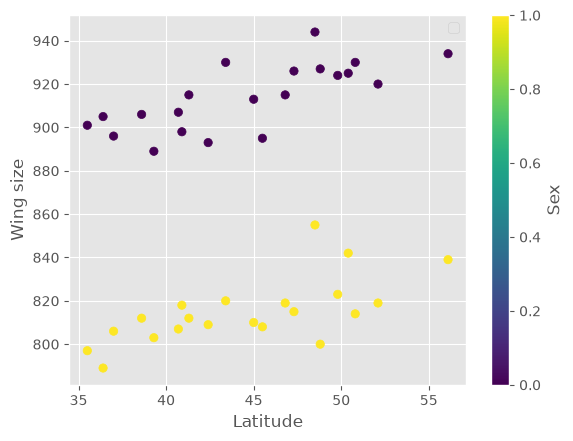

In [ ]:
# Plot the data, colour coded by sex
plt.scatter(insects.latitude, insects.wingsize, c=insects['sex'])
plt.xlabel("Latitude")
plt.ylabel("Wing size")
plt.colorbar(label="Sex")
plt.show()

#### Step 3: Instantiate a LinearRegression Object

In [5]:
insects_regression = LinearRegression()

#### Step 4: Fit the model

In [6]:
insects_regression.fit(X_insects, y_insects)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ -4.13, 1.79,-98.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['continent','latitude','sex']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,836.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


#### Step 5: Predict Values

In [7]:
# Predict the target for the whole dataset
wing_size_predictions = insects_regression.predict(X_insects)

# Predict the target for a new data point
new_insect = pd.DataFrame({
    'continent': [1],
    'latitude': [40],
    'sex': [0]
})
new_insect['wingsize'] = insects_regression.predict(new_insect)
print(f"New insect is:\n{new_insect}")

New insect is:
   continent  latitude  sex    wingsize
0          1        40    0  903.740233


#### Step 6: Plot the Predictions

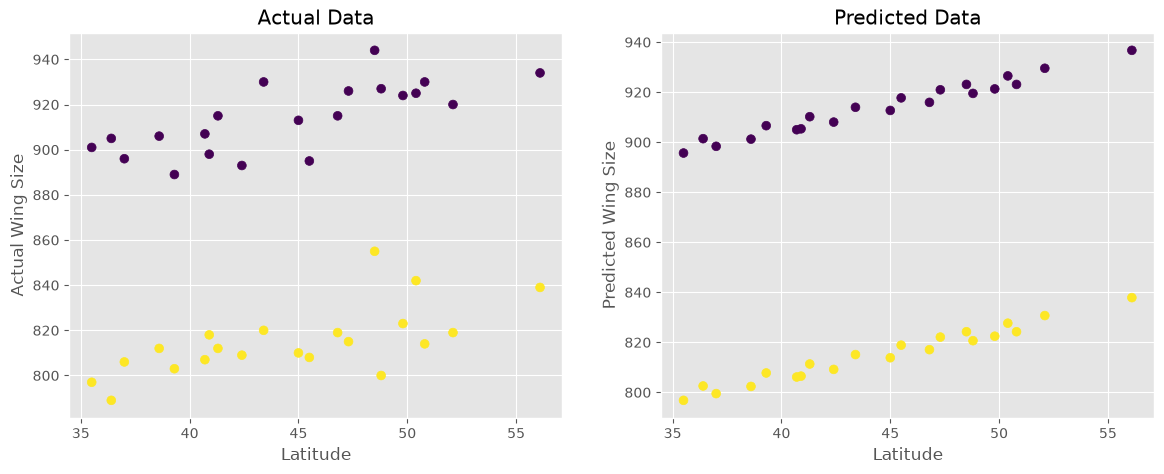

In [11]:
# Plot the predictions compared to the actual data
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].scatter(insects.latitude, insects.wingsize, c=insects['sex'], s=40)
axs[0].set_title("Actual Data")
axs[0].set_xlabel("Latitude")
axs[0].set_ylabel("Actual Wing Size")

axs[1].scatter(insects.latitude, wing_size_predictions, c=insects['sex'], s=40)
axs[1].set_title("Predicted Data")
axs[1].set_xlabel("Latitude")
axs[1].set_ylabel("Predicted Wing Size")

plt.show()

Yellow is female (1) and purple is male, when you set the colour to 'sex' it changes their colour based on the data point's position between the values which the colours are mapped between (that is why there are two distinct colours) if you were to set c = latitude you would the see gradient more clearly as the latitude varies more

#### Step 7: Evaluate The Model

In [12]:
# Get evaluative data from the model
print(f"Model coefficients: {insects_regression.coef_}")
print(f"Model y intercept: {insects_regression.intercept_}")
print(f"Model score (R squared): {insects_regression.score(X_insects, y_insects)}")
mae = mean_absolute_error(y_true=y_insects, y_pred=wing_size_predictions)
mse = mean_squared_error(y_true=y_insects, y_pred=wing_size_predictions)
print("MAE:", mae)
print("MSE:", mse)

Model coefficients: [ -4.12890383   1.79260932 -98.85714286]
Model y intercept: 836.1647645123378
Model score (R squared): 0.9585580994936529
MAE: 7.750187049787379
MSE: 110.55759329458347


In [13]:
# Optional: Manually evaluate the loss and cost of the model
model_loss = pd.DataFrame({
    'Target': y_insects,
    'Predicted result': wing_size_predictions.round(2),
    'Loss': (wing_size_predictions - y_insects) ** 2  # Squared error for each insect
})
# Cost = 1/(2m) x the sum of the squared errors (half of the MSE printed above)
model_cost = 1 / (2 * model_loss.shape[0]) * model_loss['Loss'].sum()

print(f"The cost of this model is {model_cost:.5f}")
print(model_loss)

The cost of this model is 55.27880
    Target  Predicted result        Loss
0      901            895.67   28.371693
1      896            898.36    5.580960
2      906            901.23   22.747364
3      907            905.00    4.019785
4      898            905.35   54.075165
5      893            908.04  226.276679
6      913            912.70    0.088043
7      915            915.93    0.864857
8      927            919.52   56.022300
9      924            921.31    7.247915
10     930            923.10   47.604286
11     905            901.42   12.846893
12     889            906.61  310.263942
13     915            910.20   23.044518
14     930            913.96  257.153010
15     895            917.73  516.584189
16     926            920.96   25.450156
17     944            923.11  436.546013
18     925            926.51    2.286973
19     920            929.56   91.388055
20     934            936.73    7.453704
21     797            796.82    0.033728
22     806            